In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

KS_CRIT = 1.358  # 95% point of sup |B(r) - rB(1)|
SN_CRIT = 40.1  # 95% point of G(1), from the paper

PLOTS = Path('../figures')  # every figure is also saved here
PLOTS.mkdir(exist_ok=True)

# One look per test in every plot. KS with the true sigma is the dashed black
# reference. Different markers so that curves lying on top of each other can
# be told apart.
STYLE = {
    'FB': dict(color='#0072B2', marker='o'),
    'DDB1': dict(color='#E69F00', marker='s'),
    'SN': dict(color='#009E73', marker='^'),
    'KS (true sigma)': dict(color='black', ls='--'),
}
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'lines.linewidth': 1.3,
    'lines.markersize': 3.5,
    'legend.frameon': False,
})

In [2]:
def simulate_ar1(phi, n, n_rep, rng, burn=100):
    """Returns an (n_rep, n) array, one AR(1) series per row."""
    eps = rng.standard_normal((n_rep, n + burn))
    x = np.empty_like(eps)
    x[:, 0] = eps[:, 0]
    for t in range(1, n + burn):
        x[:, t] = phi * x[:, t - 1] + eps[:, t]
    # Drop the burn-in so the start value does not matter.
    return x[:, burn:]

In [3]:
def autocov(x, max_lag):
    """Sample autocovariances at lags 0..max_lag, one row per series."""
    n = x.shape[1]
    u = x - x.mean(axis=1, keepdims=True)
    gam = np.empty((x.shape[0], max_lag + 1))
    for k in range(max_lag + 1):
        gam[:, k] = (u[:, :n - k] * u[:, k:]).sum(axis=1) / n
    return gam


def bartlett_lrv(x, bw):
    """Bartlett estimate of the long-run variance.

    bw is either one bandwidth for all series or one per series.
    """
    bw = np.broadcast_to(np.asarray(bw, dtype=float), (x.shape[0],))
    max_lag = int(np.ceil(bw.max()))
    gam = autocov(x, max_lag)
    k = np.arange(max_lag + 1)
    w = np.clip(1 - k / np.maximum(bw[:, None], 1), 0, None)
    w[:, 1:] *= 2  # lags k and -k
    return (w * gam).sum(axis=1)


def andrews_bw(x):
    """Andrews (1991) AR(1) plug-in bandwidth for the Bartlett kernel."""
    n = x.shape[1]
    u = x - x.mean(axis=1, keepdims=True)
    rho = (u[:, 1:] * u[:, :-1]).sum(axis=1) / (u[:, :-1] ** 2).sum(axis=1)
    a = 4 * rho**2 / (1 - rho**2) ** 2
    return np.minimum(1.1447 * (a * n) ** (1 / 3), n - 1)

In [4]:
def cusum(x):
    """T_n(k) for k = 1..n, one row per series."""
    n = x.shape[1]
    s = np.cumsum(x, axis=1)
    k = np.arange(1, n + 1)
    return (s - k / n * s[:, -1:]) / np.sqrt(n)


def ks_stat(x, lrv):
    return np.abs(cusum(x)).max(axis=1) / np.sqrt(lrv)


def seg_sq_sums(s):
    """sum_{t <= k} (s_t - t/k s_k)^2 for every k = 1..n.

    Expanding the square leaves only running sums of s_t^2 and t s_t,
    so all n values come out of one cumsum each.
    """
    n = s.shape[1]
    k = np.arange(1, n + 1)
    a = np.cumsum(s**2, axis=1)
    b = np.cumsum(k * s, axis=1)
    c = k * (k + 1) * (2 * k + 1) / 6  # sum of t^2
    return a - 2 * s / k * b + (s / k) ** 2 * c


def sn_stat(x):
    """Shao-Zhang G_n, one value per series."""
    n = x.shape[1]
    fwd = seg_sq_sums(np.cumsum(x, axis=1))
    # The second sum in V_n(k) is the first one for the reversed series,
    # taken over its first n - k points.
    back = seg_sq_sums(np.cumsum(x[:, ::-1], axis=1))
    v = (fwd[:, :n - 1] + back[:, n - 2::-1]) / n**2
    return (cusum(x)[:, :n - 1] ** 2 / v).max(axis=1)

In [5]:
CRIT = {'FB': KS_CRIT, 'DDB1': KS_CRIT, 'SN': SN_CRIT,
        'KS (true sigma)': KS_CRIT}


def test_stats(x, phi):
    n = x.shape[1]
    return {
        'FB': ks_stat(x, bartlett_lrv(x, n ** (1 / 3))),
        'DDB1': ks_stat(x, bartlett_lrv(x, andrews_bw(x))),
        'SN': sn_stat(x),
        # True long-run variance of AR(1) with N(0, 1) innovations.
        'KS (true sigma)': ks_stat(x, 1 / (1 - phi) ** 2),
    }


def rejection_rates(phi, n, n_rep, rng):
    stats = test_stats(simulate_ar1(phi, n, n_rep, rng), phi)
    return {m: np.mean(stats[m] > CRIT[m]) for m in stats}


rng = np.random.default_rng(2026)
rejection_rates(0.0, 200, 2000, rng)

{'FB': np.float64(0.0275),
 'DDB1': np.float64(0.0315),
 'SN': np.float64(0.0455),
 'KS (true sigma)': np.float64(0.033)}

In [6]:
phis = [-0.5, -0.2, 0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
ns = [200, 500]
methods = ['FB', 'DDB1', 'SN', 'KS (true sigma)']
n_rep = 5000

size = {}
for n in ns:
    size[n] = [rejection_rates(phi, n, n_rep, rng) for phi in phis]

width = {m: max(8, len(m) + 2) for m in methods}
for n in ns:
    print(f'n = {n}, rejection rate in %')
    print('  phi' + ''.join(f'{m:>{width[m]}}' for m in methods))
    for phi, r in zip(phis, size[n]):
        print(f'{phi:5.1f}'
              + ''.join(f'{100 * r[m]:{width[m]}.1f}' for m in methods))
    print()

n = 200, rejection rate in %
  phi      FB    DDB1      SN  KS (true sigma)
 -0.5     1.6     2.0     4.4              5.6
 -0.2     2.4     2.5     4.6              4.3
  0.0     3.0     3.8     5.3              4.0
  0.2     3.8     4.8     4.9              3.1
  0.4     4.8     4.4     5.8              2.9
  0.5     6.7     4.8     6.0              3.3
  0.6     7.9     4.0     6.6              2.3
  0.7    12.9     3.7     8.1              2.5
  0.8    20.6     2.7     8.3              2.0
  0.9    43.0     0.6    13.6              0.7

n = 500, rejection rate in %
  phi      FB    DDB1      SN  KS (true sigma)
 -0.5     2.2     2.5     4.8              4.9
 -0.2     2.8     2.7     4.8              4.4
  0.0     4.0     4.2     5.3              4.6
  0.2     4.6     5.2     5.3              3.9
  0.4     5.1     4.7     5.0              3.5
  0.5     6.8     5.4     5.3              3.9
  0.6     8.9     5.8     6.2              3.7
  0.7    10.8     4.8     6.1              3.0
 

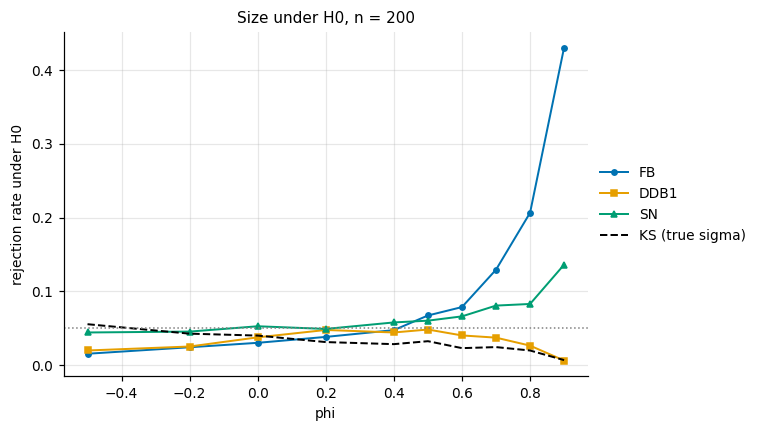

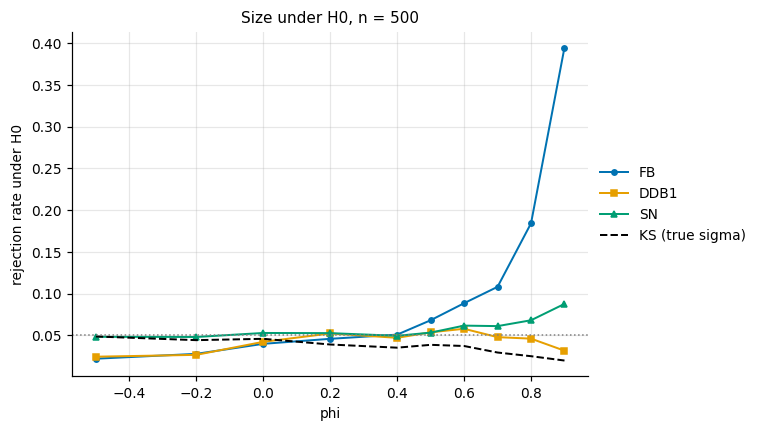

In [7]:
for n in ns:
    fig, ax = plt.subplots(figsize=(7, 4))
    for m in methods:
        ax.plot(phis, [r[m] for r in size[n]], label=m, **STYLE[m])
    ax.axhline(0.05, color='gray', ls=':', lw=1)
    ax.set_title(f'Size under H0, n = {n}')
    ax.set_xlabel('phi')
    ax.set_ylabel('rejection rate under H0')
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    fig.savefig(PLOTS / f'size_under_H0_n{n}.png')
    plt.show()

In [8]:
# Table 2 of the paper, sizes in % for phi = 0, 0.5, 0.8.
paper = {
    200: {'FB': [3.5, 6.9, 20.2], 'DDB1': [2.5, 4.9, 2.4],
          'SN': [4.9, 6.1, 8.6]},
    500: {'FB': [3.6, 6.2, 18.4], 'DDB1': [2.7, 4.7, 4.5],
          'SN': [5.2, 5.3, 6.5]},
}

print('mine / paper')
for n in ns:
    for i, phi in enumerate([0.0, 0.5, 0.8]):
        r = size[n][phis.index(phi)]
        cells = [f'{m} {100 * r[m]:4.1f} / {paper[n][m][i]:4.1f}'
                 for m in paper[n]]
        print(f'n = {n}, phi = {phi}:   ' + '   '.join(cells))

mine / paper
n = 200, phi = 0.0:   FB  3.0 /  3.5   DDB1  3.8 /  2.5   SN  5.3 /  4.9
n = 200, phi = 0.5:   FB  6.7 /  6.9   DDB1  4.8 /  4.9   SN  6.0 /  6.1
n = 200, phi = 0.8:   FB 20.6 / 20.2   DDB1  2.7 /  2.4   SN  8.3 /  8.6
n = 500, phi = 0.0:   FB  4.0 /  3.6   DDB1  4.2 /  2.7   SN  5.3 /  5.2
n = 500, phi = 0.5:   FB  6.8 /  6.2   DDB1  5.4 /  4.7   SN  5.3 /  5.3
n = 500, phi = 0.8:   FB 18.4 / 18.4   DDB1  4.6 /  4.5   SN  6.8 /  6.5


In [9]:
power_phis = [0.0, 0.5, 0.8]
# The paper stops at eta = 6, but DDB1's power often collapses only later.
etas = np.arange(0, 12.01, 0.1)
n_rep_power = 2000

raw_power = {}
power = {}  # size-adjusted
adj_crit = {}
for n in ns:
    jump = (np.arange(1, n + 1) > n / 2).astype(float)
    for phi in power_phis:
        null = test_stats(simulate_ar1(phi, n, n_rep, rng), phi)
        crit = {m: np.quantile(null[m], 0.95) for m in methods}
        adj_crit[n, phi] = crit
        u = simulate_ar1(phi, n, n_rep_power, rng)
        raw = {m: [] for m in methods}
        adj = {m: [] for m in methods}
        for eta in etas:
            stats = test_stats(eta * jump + u, phi)
            for m in methods:
                raw[m].append(np.mean(stats[m] > CRIT[m]))
                adj[m].append(np.mean(stats[m] > crit[m]))
        raw_power[n, phi] = raw
        power[n, phi] = adj

print('size-adjusted critical values (asymptotic: KS 1.358, SN 40.1)')
for (n, phi), crit in adj_crit.items():
    vals = '   '.join(f'{m} {crit[m]:6.2f}' for m in methods)
    print(f'n = {n}, phi = {phi}:   {vals}')

size-adjusted critical values (asymptotic: KS 1.358, SN 40.1)
n = 200, phi = 0.0:   FB   1.30   DDB1   1.31   SN  41.71   KS (true sigma)   1.32
n = 200, phi = 0.5:   FB   1.40   DDB1   1.34   SN  44.99   KS (true sigma)   1.28
n = 200, phi = 0.8:   FB   1.69   DDB1   1.28   SN  53.17   KS (true sigma)   1.18
n = 500, phi = 0.0:   FB   1.31   DDB1   1.33   SN  41.30   KS (true sigma)   1.32
n = 500, phi = 0.5:   FB   1.41   DDB1   1.37   SN  41.70   KS (true sigma)   1.31
n = 500, phi = 0.8:   FB   1.69   DDB1   1.35   SN  46.46   KS (true sigma)   1.26


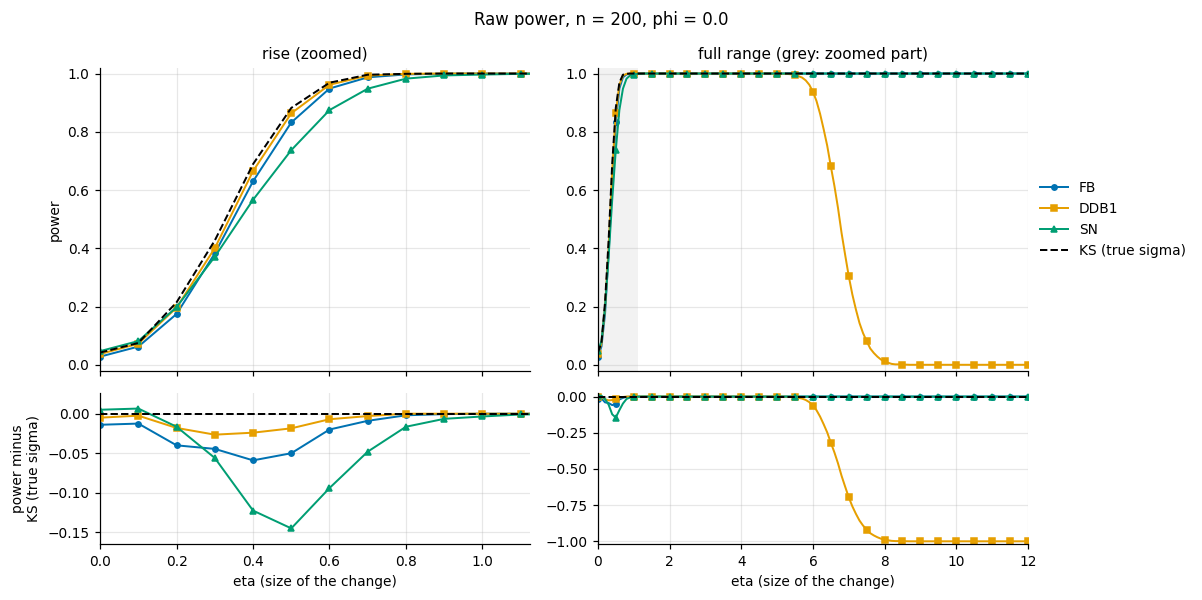

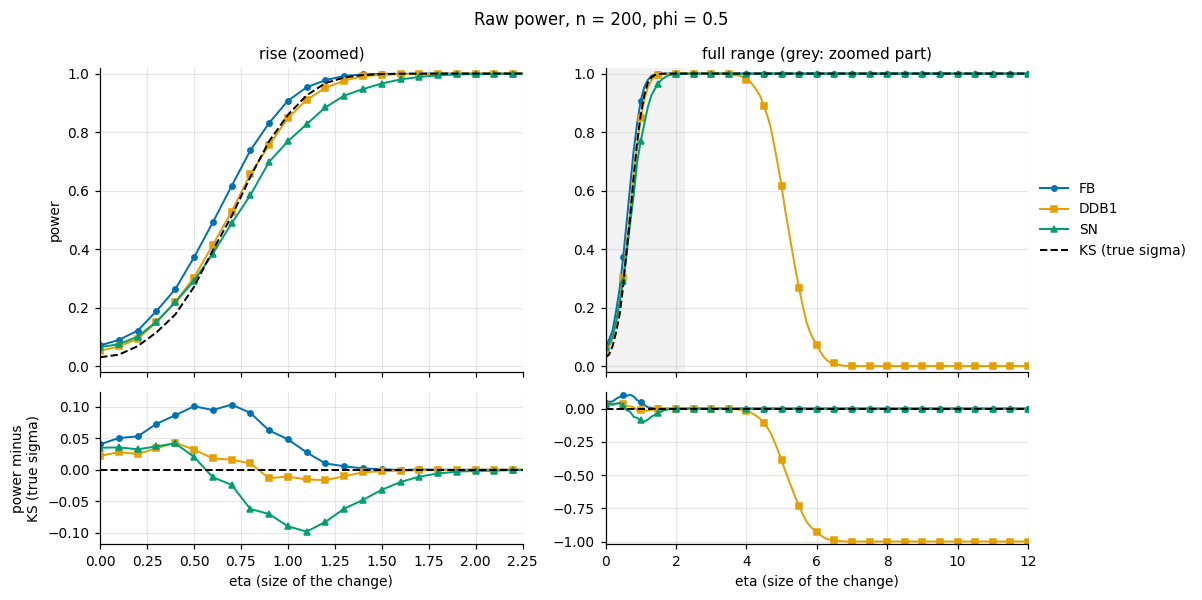

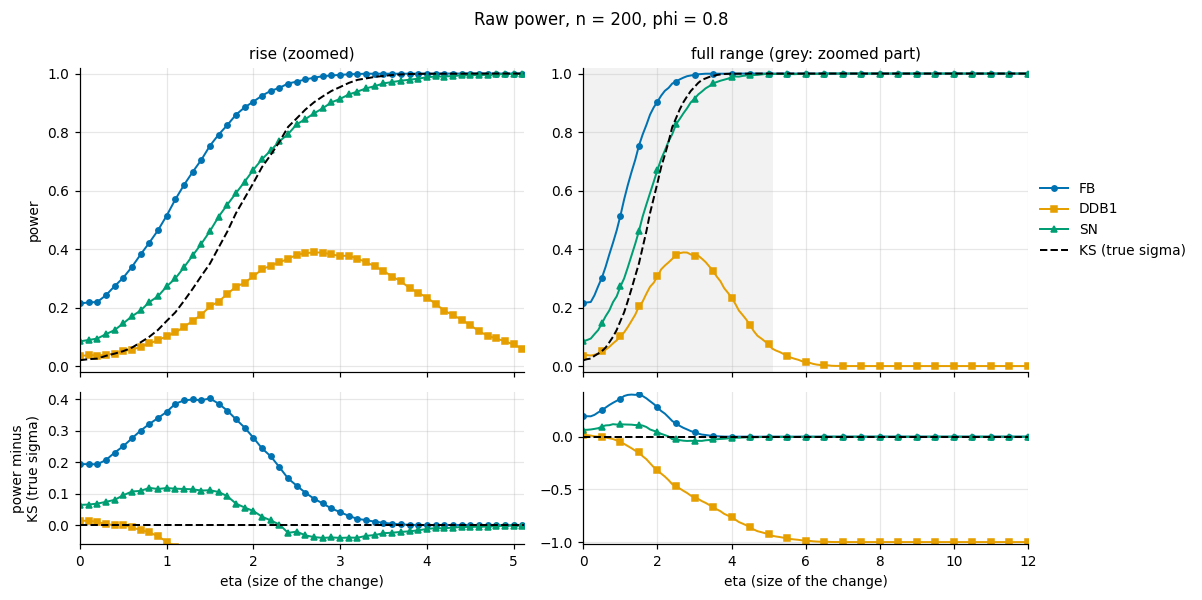

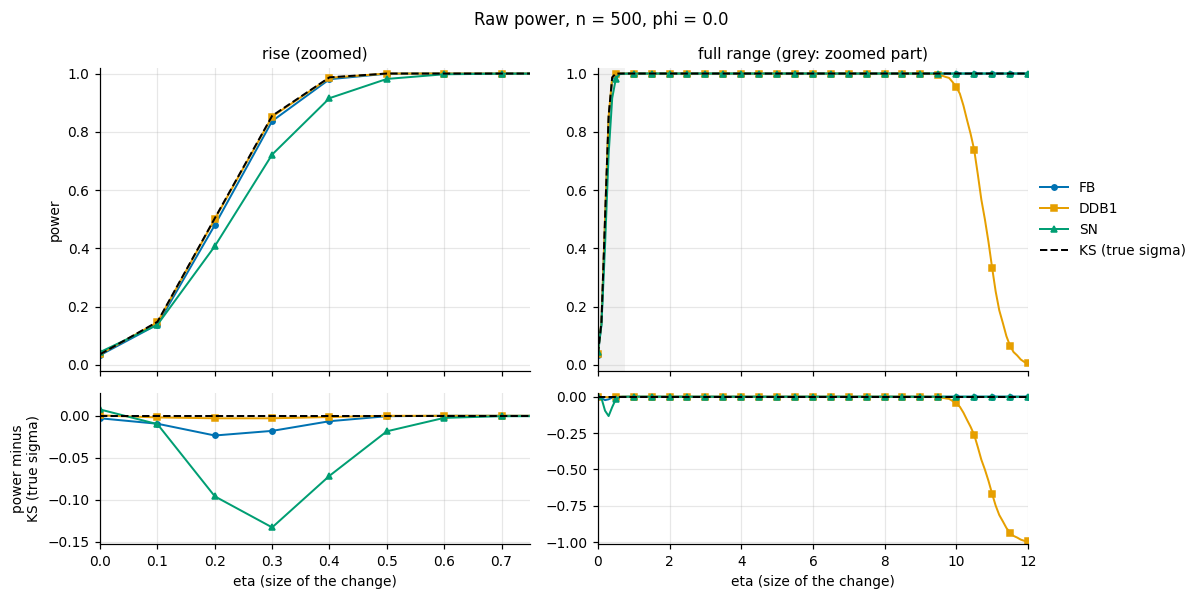

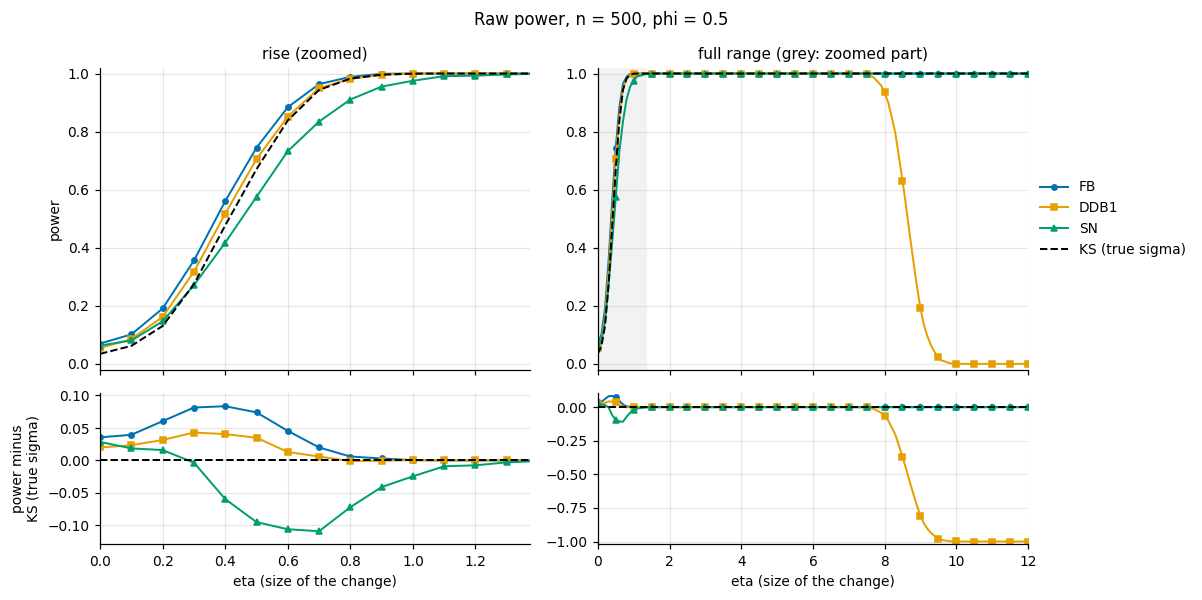

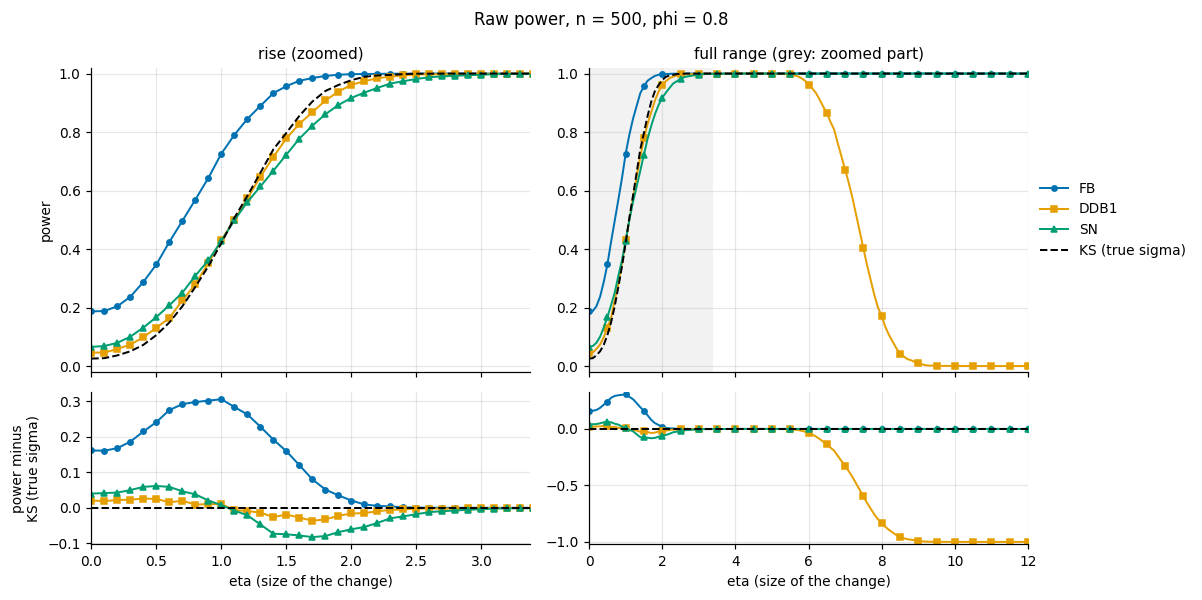

In [10]:
def rise_end(curve):
    """First eta at which every test except DDB1 has power >= 0.99."""
    lowest = np.min([curve[m] for m in methods if m != 'DDB1'], axis=0)
    done = np.flatnonzero(lowest >= 0.99)
    return etas[done[0]] if done.size else etas[-1]


def gap_limits(gaps, shown, tests):
    lo = min(gaps[m][shown].min() for m in tests)
    hi = max(gaps[m][shown].max() for m in tests)
    return lo - 0.02, hi + 0.02


def plot_power(curves, kind):
    """One figure per (n, phi).

    Left: the rise, zoomed in, where SN falls behind. Right: the whole eta
    range, where DDB1's power collapses. Bottom row: power minus
    KS (true sigma).
    """
    for n in ns:
        for phi in power_phis:
            curve = curves[n, phi]
            gaps = {m: np.subtract(curve[m], curve['KS (true sigma)'])
                    for m in methods}
            x_max = min(etas[-1], 1.25 * rise_end(curve))
            zoomed = etas <= x_max + 1e-9

            fig, axes = plt.subplots(
                2, 2, figsize=(11, 5.5), sharex='col',
                gridspec_kw={'height_ratios': [3, 1.5]})
            left, right = axes[:, 0], axes[:, 1]
            for m in methods:
                left[0].plot(etas, curve[m], **STYLE[m])
                left[1].plot(etas, gaps[m], **STYLE[m])
                right[0].plot(etas, curve[m], label=m, markevery=5,
                              **STYLE[m])
                right[1].plot(etas, gaps[m], markevery=5, **STYLE[m])

            left[0].set_title('rise (zoomed)')
            left[1].set_xlim(0, x_max)
            # DDB1 is left out of this range so that its collapse does not
            # squash the other gaps. It is shown in full on the right.
            others = [m for m in methods if m != 'DDB1']
            left[1].set_ylim(gap_limits(gaps, zoomed, others))
            right[0].set_title('full range (grey: zoomed part)')
            right[0].axvspan(0, x_max, color='gray', alpha=0.1, lw=0)
            right[0].legend(loc='center left', bbox_to_anchor=(1, 0.5))
            right[1].set_xlim(0, etas[-1])
            right[1].set_ylim(gap_limits(gaps, etas >= 0, methods))

            for ax in axes[0]:
                ax.set_ylim(-0.02, 1.02)
            for ax in axes[1]:
                ax.set_xlabel('eta (size of the change)')
            left[0].set_ylabel('power')
            left[1].set_ylabel('power minus\nKS (true sigma)')
            fig.suptitle(f'{kind} power, n = {n}, phi = {phi}')
            plt.tight_layout()
            name = kind.lower().replace('-', '_')
            fig.savefig(PLOTS / f'power_{name}_n{n}_phi{phi}.png')
            plt.show()


plot_power(raw_power, 'Raw')

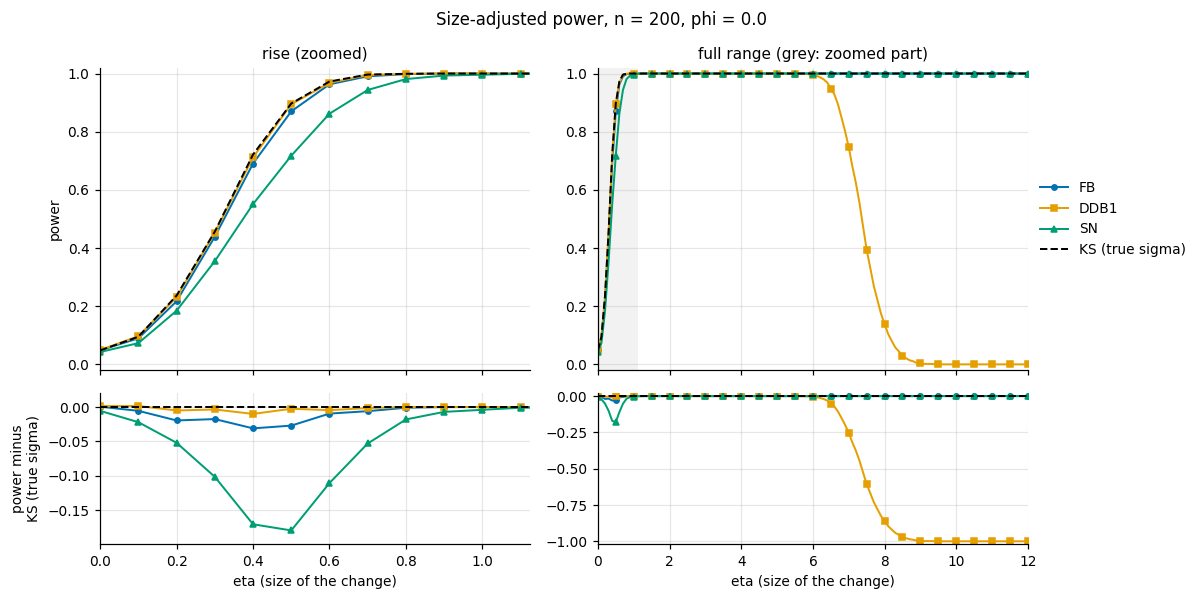

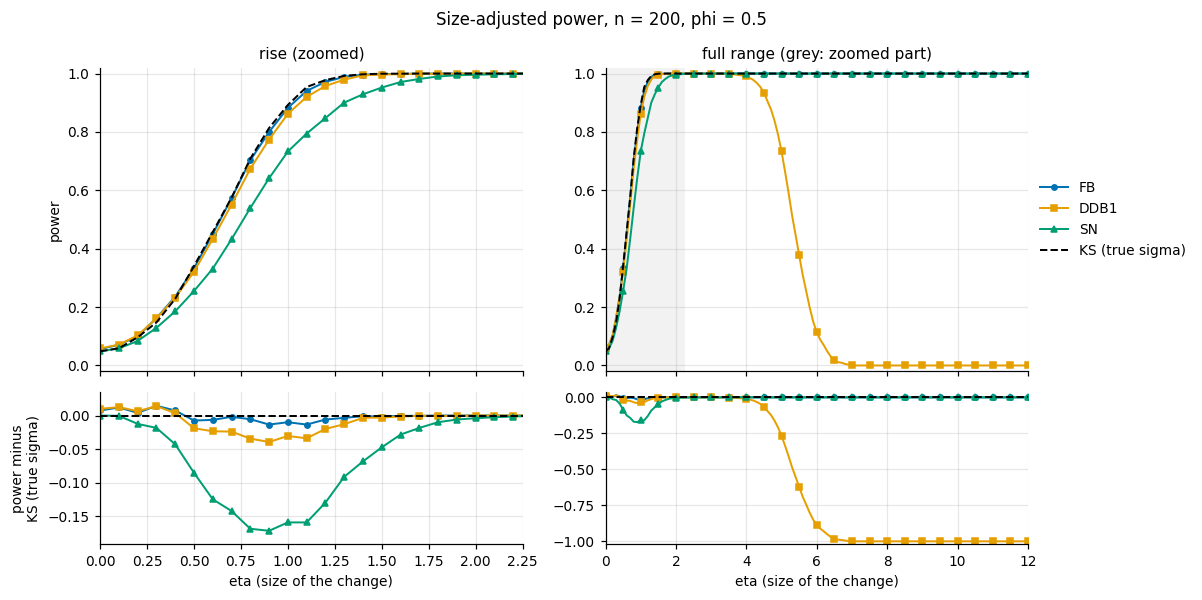

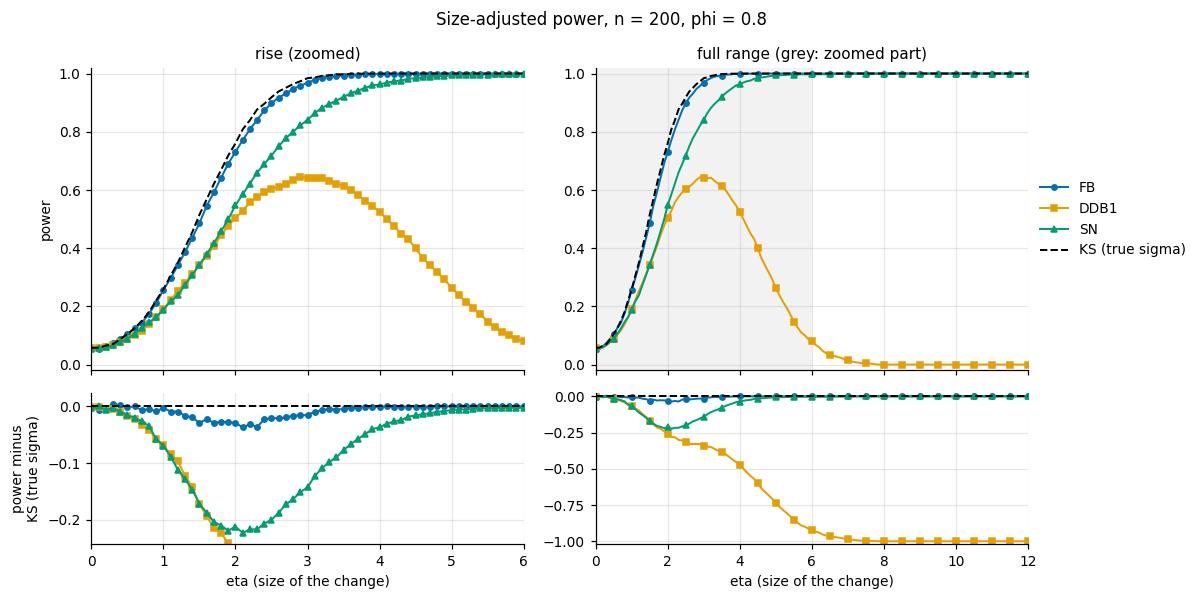

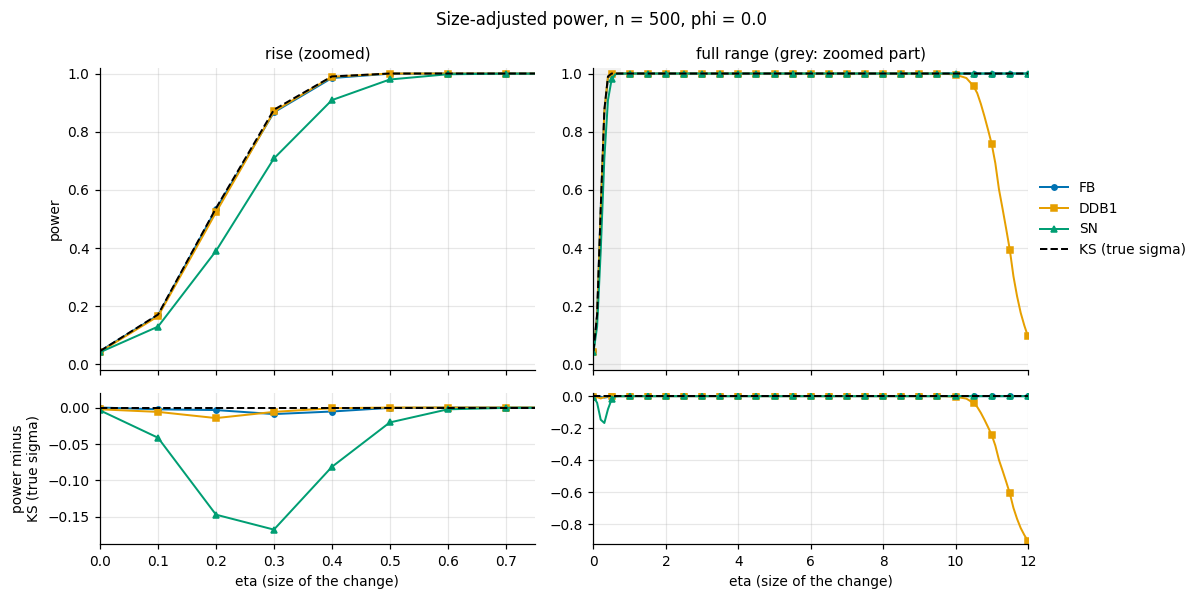

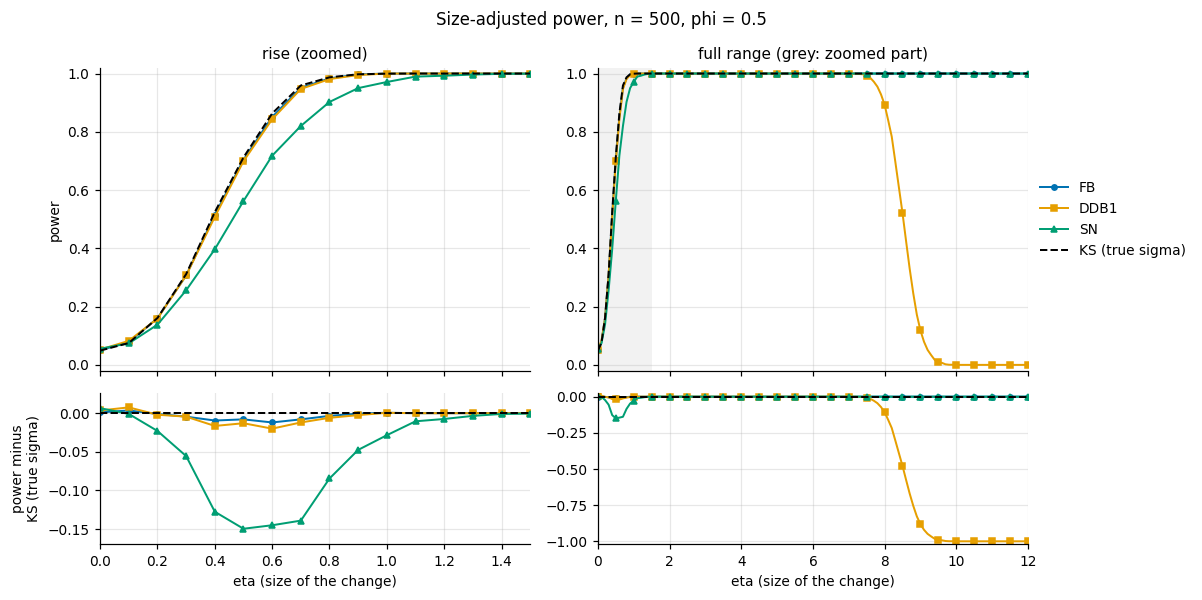

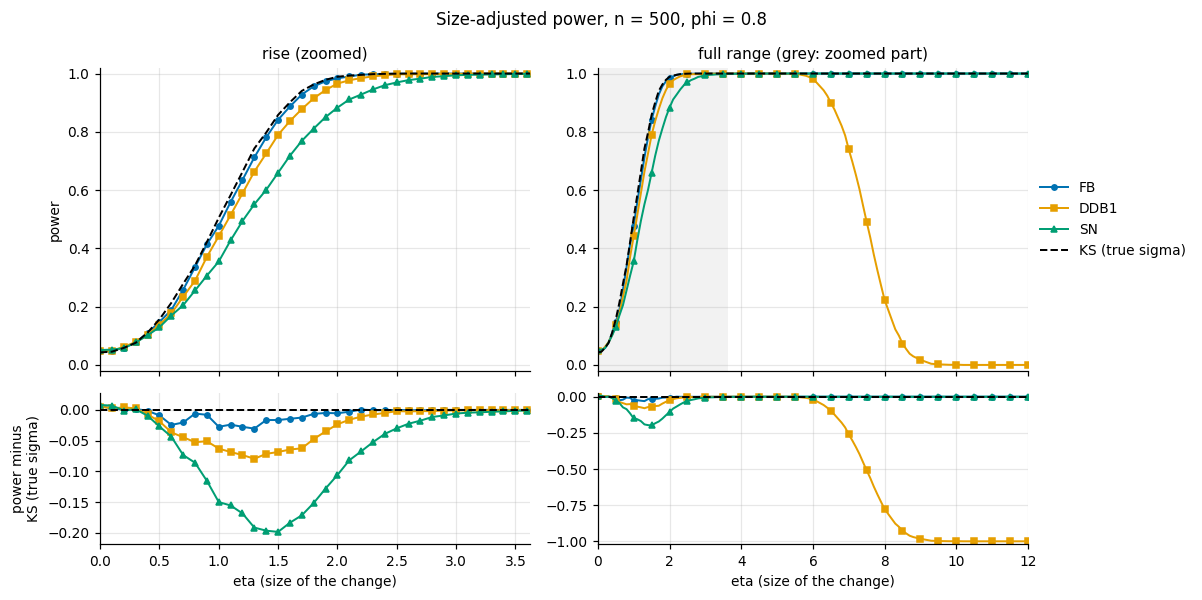

In [11]:
plot_power(power, 'Size-adjusted')

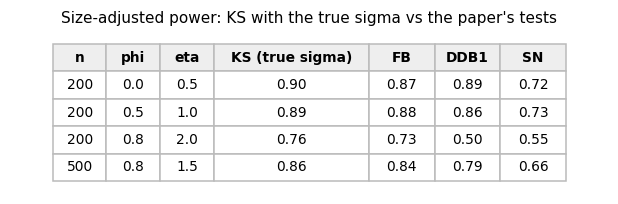

In [12]:
# Size-adjusted power at a few points in the middle of the curves.
points = [(200, 0.0, 0.5), (200, 0.5, 1.0), (200, 0.8, 2.0), (500, 0.8, 1.5)]
cols = ['KS (true sigma)', 'FB', 'DDB1', 'SN']
rows = []
for n, phi, eta in points:
    i = np.argmin(np.abs(etas - eta))
    rows.append([str(n), str(phi), str(eta)]
                + [f'{power[n, phi][m][i]:.2f}' for m in cols])

fig, ax = plt.subplots(figsize=(7, 1.9))
ax.axis('off')
table = ax.table(cellText=rows, colLabels=['n', 'phi', 'eta'] + cols,
                 loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
widths = [0.09, 0.09, 0.09, 0.26, 0.11, 0.11, 0.11]
for (r, c), cell in table.get_celld().items():
    cell.set_width(widths[c])
    cell.set_height(0.17)
    cell.set_edgecolor('#bbbbbb')
    if r == 0:
        cell.set_text_props(weight='bold')
        cell.set_facecolor('#eeeeee')
ax.set_title("Size-adjusted power: KS with the true sigma vs the paper's "
             'tests')
fig.savefig(PLOTS / 'table_size_adjusted_power.png')
plt.show()

KS with the true sigma vs the paper's tests (size-adjusted):

| n, phi, eta | KS (true sigma) | FB | DDB1 | SN |
|---|---|---|---|---|
| 200, 0.0, 0.5 | 0.90 | 0.87 | 0.89 | 0.72 |
| 200, 0.5, 1 | 0.89 | 0.88 | 0.86 | 0.73 |
| 200, 0.8, 2 | 0.76 | 0.73 | 0.50 | 0.55 |
| 500, 0.8, 1.5 | 0.86 | 0.84 | 0.79 | 0.66 |